### Installing required libraries

In [1]:
# Install required libraries
!pip install seaborn missingno xgboost catboost regex scikit-learn pandas numpy imblearn lightgbm polars


### Importing all libraries 

In [2]:
# Core libraries
import pandas as pd
import numpy as np
import csv
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

# Model selection
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    make_scorer
)


### Import additional items as needed...

In [3]:
# Model selection utilities
from sklearn.model_selection import (
    KFold,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score
)

# Preprocessing & pipelines
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline

# Models & balancing
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE

# Metrics (only those not already imported in Script 2)
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# Plotly visualization
import plotly
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")


### Loading CSV data 

In [4]:
diabetes = pd.read_csv('raw/diabetic_data.csv')

# CLEANING AND TRANSFORMING THE DATASET

In [5]:
#@title GENDER ENCODING
# Keep only Male, Female, and Other rows
diabetes = diabetes[diabetes['gender'].isin(['Male', 'Female', 'Other'])].copy()

# Create indicator: 1 = Male, 0 = Female or Other
diabetes['GenderMale'] = (diabetes['gender'] == 'Male').astype(int)


In [6]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [7]:
# Mapping Admission Type ID to interpretable binary categories:
# 1 = Emergency/Urgent/Trauma
# 0 = Elective/Newborn/NotAvailable/NULL/NotMapped

admission_type_binary_map = {
    1: 1,  # Emergency
    2: 1,  # Urgent
    7: 1,  # TraumaCenter

    3: 0,  # Elective
    4: 0,  # Newborn
    5: 0,  # NotAvailable
    6: 0,  # NULL
    8: 0   # NotMapped
}

diabetes["admission_type_id"] = (
    diabetes["admission_type_id"]
    .map(admission_type_binary_map)
    .fillna(0)
    .astype(int)
)


In [8]:
# Binary mapping for discharge disposition:
# 0 = routine / lower‑risk discharge
# 1 = adverse / higher‑risk discharge

discharge_disposition_binary_map = {
    # lower‑risk / routine
    1: 0,   # Home
    6: 0,   # HomeHealth
    8: 0,   # HomeIVCare
    18: 0,  # NULL
    25: 0,  # NotMapped

    # higher‑risk / adverse outcomes
    2: 1,   # ShortTermHospital
    3: 1,   # SNF
    4: 1,   # ICF
    5: 1,   # OtherInpatientCare
    7: 1,   # LeftAMA
    9: 1,   # AdmittedToThisHospital
    10: 1,  # NeonateToAnotherHospital
    11: 1,  # Expired
    12: 1,  # StillPatient
    13: 1,  # HospiceHome
    14: 1,  # HospiceFacility
    15: 1,  # SwingBed
    16: 1,  # OutpatientServicesOtherInstitution
    17: 1,  # OutpatientServicesThisInstitution
    19: 1,  # ExpiredHomeMedicaid
    20: 1,  # ExpiredFacilityMedicaid
    21: 1,  # ExpiredUnknownMedicaid
    22: 1,  # RehabFacility
    23: 1,  # LongTermCareHospital
    24: 1,  # MedicaidNursingFacility
    27: 1,  # FederalHealthCareFacility
    28: 1,  # PsychiatricHospital
    29: 1,  # CriticalAccessHospital
    30: 1   # OtherHealthcareInstitution
}

diabetes["discharge_disposition_id"] = (
    diabetes["discharge_disposition_id"]
        .map(discharge_disposition_binary_map)
        .fillna(0)
        .astype(int)
)


In [9]:
def icd_to_chapter(code):
    try:
        code = float(code)
    except:
        return "Unknown"

    if 1 <= code <= 139:
        return "Infectious and Parasitic Diseases"
    elif 140 <= code <= 239:
        return "Neoplasms"
    elif 240 <= code <= 279:
        return "Endocrine/Metabolic"
    elif 280 <= code <= 289:
        return "Blood Diseases"
    elif 290 <= code <= 319:
        return "Mental Disorders"
    elif 320 <= code <= 389:
        return "Nervous System"
    elif 390 <= code <= 459:
        return "Circulatory System"
    elif 460 <= code <= 519:
        return "Respiratory System"
    elif 520 <= code <= 579:
        return "Digestive System"
    elif 580 <= code <= 629:
        return "Genitourinary System"
    elif 630 <= code <= 679:
        return "Pregnancy/Childbirth"
    elif 680 <= code <= 709:
        return "Skin/Subcutaneous"
    elif 710 <= code <= 739:
        return "Musculoskeletal"
    elif 740 <= code <= 759:
        return "Congenital Anomalies"
    elif 760 <= code <= 779:
        return "Perinatal Conditions"
    elif 780 <= code <= 799:
        return "Symptoms/Ill-defined"
    elif 800 <= code <= 999:
        return "Injury/Poisoning"
    elif code >= 1000:
        return "Unknown"
    else:
        return "Unknown"


In [10]:
for col in ["diag_1", "diag_2", "diag_3"]:
    diabetes[col + "_chapter"] = diabetes[col].apply(icd_to_chapter)


In [11]:
# ============================================================
# Binary mapping for ICD diagnosis chapters
# ============================================================
diag_binary_map = {
    "Endocrine/Metabolic": 1,
    "Circulatory System": 1,
    "Respiratory System": 1,
    "Neoplasms": 1,
    "Infectious and Parasitic Diseases": 1,
    "Injury/Poisoning": 1,
    "Genitourinary System": 1,
    "Nervous System": 1,
    "Blood Diseases": 1,
    "Mental Disorders": 1,

    "Symptoms/Ill-defined": 0,
    "Skin/Subcutaneous": 0,
    "Musculoskeletal": 0,
    "Digestive System": 0,
    "Pregnancy/Childbirth": 0,
    "Congenital Anomalies": 0,
    "V-Codes": 0,
    "E-Codes": 0,
    "Unknown": 0
}

for col in ["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]:
    diabetes[col] = (
        diabetes[col]
            .map(diag_binary_map)
            .fillna(0)
            .astype(int)
    )


In [12]:
#@title DIABEST MEDICATION ENCODING
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 0 if x == "No" else 1
)

In [13]:
#@title READMITTED ENCODING
# Created indicator column for readmission within 30 days
# readmit_less_30 = 1 if readmitted is "<30", else 0

diabetes['readmit_less_30'] = (diabetes['readmitted'] == '<30').astype(int)

In [14]:
#@title RACE ENCODING
diabetes['RaceCaucasian'] = (diabetes['race'] == 'Caucasian').astype(int)
diabetes['RaceAfricanAmerican'] = (diabetes['race'] == 'AfricanAmerican').astype(int)
diabetes['RaceOther'] = (~diabetes['race'].isin(['Caucasian', 'AfricanAmerican'])).astype(int)

In [15]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'GenderMale', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter',
       'readmit_l

In [16]:
#@title drop 1 intial columns
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'payer_code', 'medical_specialty',
       'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'readmitted'
], axis=1)

In [17]:
print(cleandiabetes.columns)

Index(['admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses', 'diabetesMed', 'GenderMale',
       'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter', 'readmit_less_30',
       'RaceCaucasian', 'RaceAfricanAmerican', 'RaceOther'],
      dtype='str')


### Creating 3 Dataframes from cleandiabetes dataset

In [18]:
numerical = [ 'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_emergency',
    'number_outpatient',
    'number_inpatient',
    'number_diagnoses' ]

### MISSING DATA

In [19]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [20]:
print("Missing Data in Sub1:")
display(missing(cleandiabetes))



Missing Data in Sub1:


,Missing_Number,Missing_Percent
admission_type_id,0,0.0
discharge_disposition_id,0,0.0
admission_source_id,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0


### CORRELATION

In [21]:
#@title Correlation Matrices
print("Correlation Matrix for Sub1")
display(cleandiabetes[numerical].corr())

Correlation Matrix for Sub1


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_emergency,number_outpatient,number_inpatient,number_diagnoses
time_in_hospital,1.000000,0.318429,0.191497,0.466137,-0.009683,-0.008919,0.073619,0.220153
num_lab_procedures,0.318429,1.000000,0.058105,0.268176,-0.002282,-0.007606,0.039225,0.152737
num_procedures,0.191497,0.058105,1.000000,0.385761,-0.038175,-0.024813,-0.066226,0.073769
num_medications,0.466137,0.268176,0.385761,1.000000,0.013180,0.045198,0.064196,0.261529
number_emergency,-0.009683,-0.002282,-0.038175,0.013180,1.000000,0.091457,0.266557,0.055536
number_outpatient,-0.008919,-0.007606,-0.024813,0.045198,0.091457,1.000000,0.107334,0.094148
number_inpatient,0.073619,0.039225,-0.066226,0.064196,0.266557,0.107334,1.000000,0.104703
number_diagnoses,0.220153,0.152737,0.073769,0.261529,0.055536,0.094148,0.104703,1.000000


In [22]:
print("Correlation for Sub1 grouped by readmit_less_30")
display(cleandiabetes.groupby('readmit_less_30')[numerical].corr())


Correlation for Sub1 grouped by readmit_less_30


time_in_hospital  num_lab_procedures  \
readmit_less_30                                                            
0               time_in_hospital            1.000000            0.317966   
                num_lab_procedures          0.317966            1.000000   
                num_procedures              0.184436            0.052939   
                num_medications             0.463447            0.263577   
                number_emergency           -0.003929            0.004752   
                number_outpatient          -0.008027           -0.009679   
                number_inpatient            0.081365            0.044138   
                number_diagnoses            0.222743            0.153452   
1               time_in_hospital            1.000000            0.317655   
                num_lab_procedures          0.317655            1.000000   
                num_procedures              0.256572            0.104734   
                num_medications             0.479381            0.300945   
                number_emergency           -0.054951           -0.046064   
                number_outpatient          -0.022948            0.005296   
                number_inpatient            0.011970            0.004974   
                number_diagnoses            0.182704            0.138825   

                                    num_procedures  num_medications  \
readmit_less_30                                                       
0               time_in_hospital          0.184436         0.463447   
                num_lab_procedures        0.052939         0.263577   
                num_procedures            1.000000         0.385402   
                num_medications           0.385402         1.000000   
                number_emergency         -0.036941         0.017059   
                number_outpatient        -0.023116         0.044064   
                number_inpatient         -0.063103         0.066991   
                number_diagnoses          0.071891         0.261232   
1               time_in_hospital          0.256572         0.479381   
                num_lab_procedures        0.104734         0.300945   
                num_procedures            1.000000         0.396435   
                num_medications           0.396435         1.000000   
                number_emergency         -0.044692        -0.019015   
                number_outpatient        -0.036554         0.048016   
                number_inpatient         -0.084559         0.028102   
                number_diagnoses          0.098215         0.251496   

                                    number_emergency  number_outpatient  \
readmit_less_30                                                           
0               time_in_hospital           -0.003929          -0.008027   
                num_lab_procedures          0.004752          -0.009679   
                num_procedures             -0.036941          -0.023116   
                num_medications             0.017059           0.044064   
                number_emergency            1.000000           0.091213   
                number_outpatient           0.091213           1.000000   
                number_inpatient            0.241276           0.106594   
                number_diagnoses            0.056898           0.093655   
1               time_in_hospital           -0.054951          -0.022948   
                num_lab_procedures         -0.046064           0.005296   
                num_procedures             -0.044692          -0.036554   
                num_medications            -0.019015           0.048016   
                number_emergency            1.000000           0.094259   
                number_outpatient           0.094259           1.000000   
                number_inpatient            0.316596           0.113480   
                number_diagnoses            0.036837           0.091372   

                                    n

In [23]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


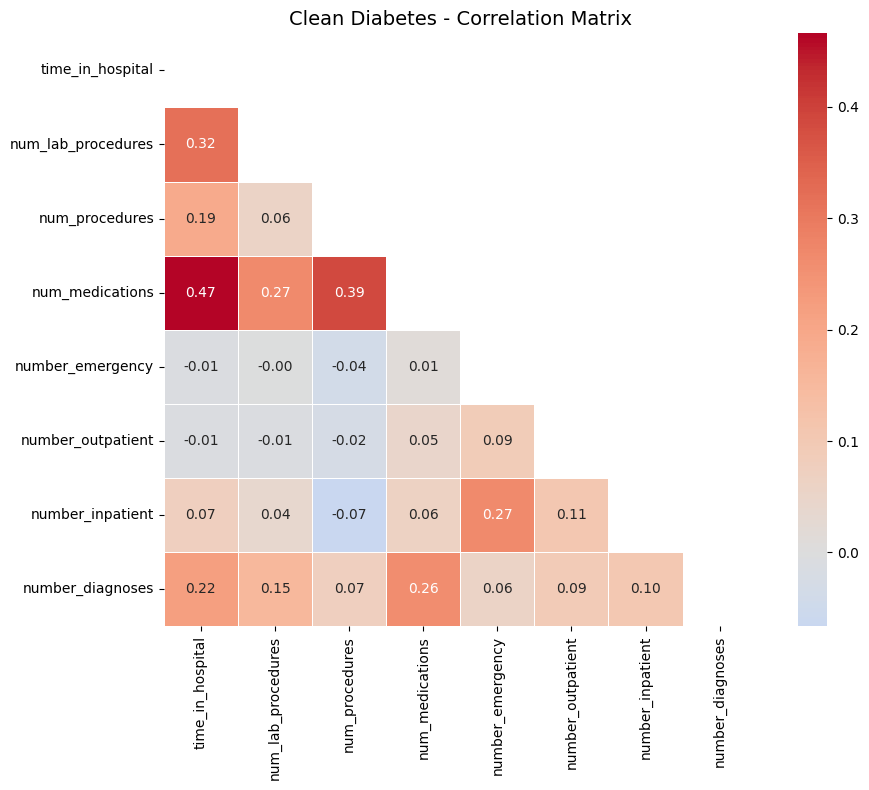

In [24]:
plot_corr_heatmap(cleandiabetes, numerical, "Clean Diabetes - Correlation Matrix")


## Breaking the data up into Train & Test

In [25]:
#@title Setting Up Data for Modeling 
#Uses the cleandiabetes dataset for modeling.
DataTesting = cleandiabetes.copy() #change it to sub2 or Sub3 to test each dataset

In [26]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 71234
Validation size: 15264
Test size: 15265
Total: 101763


In [27]:
DataTesting.readmit_less_30.value_counts()

readmit_less_30
0    90406
1    11357
Name: count, dtype: int64

In [28]:
train_df.readmit_less_30.value_counts()

readmit_less_30
0    63318
1     7916
Name: count, dtype: int64

In [29]:
valid_df.readmit_less_30.value_counts()

readmit_less_30
0    13519
1     1745
Name: count, dtype: int64

In [30]:
test_df.readmit_less_30.value_counts()

readmit_less_30
0    13569
1     1696
Name: count, dtype: int64

## Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### 1. RANDOME OVERSAMPLING: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [31]:
def balance_random_oversample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_pos_over = resample(
        df_pos,
        replace=True,
        n_samples=len(df_neg),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_neg, df_pos_over])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 2. SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

In [32]:
def balance_smote(df, target='readmit_less_30', random_state=42):
    X = df.drop(columns=[target])
    y = df[target]

    sm = SMOTE(random_state=random_state)
    X_res, y_res = sm.fit_resample(X, y)

    df_bal = pd.concat(
        [pd.DataFrame(X_res, columns=X.columns),
         pd.Series(y_res, name=target)],
        axis=1
    )

    return df_bal

#### 3. RANDOM UNDERSAMPLING
Random Undersampling reduces the size of the majority class by randomly removing samples until it matches the minority class count. This creates a balanced dataset without generating synthetic data.

In [33]:
def balance_random_undersample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_neg_under = df_neg.sample(
        n=len(df_pos),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_pos, df_neg_under])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 4. SMOTEENN


In [34]:
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE

def apply_smoteenn(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTEENN hybrid resampling:
    - SMOTE oversamples the minority class
    - ENN removes noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_enn = SMOTEENN(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_enn.fit_resample(X, y)
    return X_resampled, y_resampled

#### 5. SMOTETOMEK

In [35]:
from imblearn.combine import SMOTETomek

def apply_smotetomek(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTETomek hybrid resampling:
    - SMOTE oversamples the minority class
    - Tomek Links remove borderline/noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_tomek = SMOTETomek(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_tomek.fit_resample(X, y)
    return X_resampled, y_resampled


#### Prevalence Caculation Function

In [36]:
def calc_prevalence(y_actual):
    """
    Calculate the prevalence (ratio of positive class = 1)
    in a binary target array or Series.
    """
    y_actual = pd.Series(y_actual)
    return y_actual.mean()

<h2 style="color:#e63946;">CHANGE THE IMBALANCE TECHNIQUE HERE</h2>
“Remove the # to activate a specific technique. Add the # back to deactivate it.”


In [37]:
# 1. Split train_df into X and y
X_train = train_df.drop(columns=["readmit_less_30"])
y_train = train_df["readmit_less_30"]

# 2. Apply SMOTEENN
X_bal, y_bal = apply_smotetomek(X_train, y_train)

# 3. Combine back into a single DataFrame (optional)
train_balanced = X_bal.copy()
train_balanced["readmit_less_30"] = y_bal

# 4. Check prevalence
print(
    "Train balanced prevalence (n = %d): %.3f" %
    (len(train_balanced), calc_prevalence(train_balanced['readmit_less_30']))
)


Train balanced prevalence (n = 125360): 0.500


In [38]:
train_balanced.readmit_less_30.value_counts()

readmit_less_30
0    62680
1    62680
Name: count, dtype: int64

In [39]:
X_train = train_balanced.drop('readmit_less_30',axis=1)

y_train = train_balanced['readmit_less_30']

X_valid = valid_df.drop('readmit_less_30',axis=1)

y_valid = valid_df['readmit_less_30']

X_test = test_df.drop('readmit_less_30',axis=1)

y_test = test_df['readmit_less_30']

<h2 style="color:#e63946;">CHANGE THE SETS HERE FOR SCALER</h2>

In [40]:
scale_cols = numerical
# -----------------------------------------
# 1. Fit the scaler on TRAINING data only
# -----------------------------------------
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# -----------------------------------------
# 2. Transform VALIDATION and TEST sets
# -----------------------------------------
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])


In [41]:
X_train.head()

,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,GenderMale,diag_1_chapter,diag_2_chapter,diag_3_chapter,RaceCaucasian,RaceAfricanAmerican,RaceOther
0,1,1,7,2.613255,1.668902,3.030131,1.088170,-0.26563,-0.199878,0.179837,0.826730,0,1,1,1,1,0,1,0
1,1,0,7,1.927219,0.082230,-0.729020,-0.277407,-0.26563,-0.199878,-0.508688,0.826730,1,0,1,1,1,1,0,0
2,1,0,7,-0.130889,-0.224867,-0.729020,-0.649837,-0.26563,-0.199878,-0.508688,-1.325653,0,0,1,0,1,1,0,0
3,1,0,1,-0.473907,-0.787880,-0.729020,-0.029121,-0.26563,-0.199878,0.179837,0.826730,1,0,1,1,1,1,0,0
4,1,0,7,-0.130889,-0.224867,-0.102495,0.467453,-0.26563,-0.199878,0.179837,0.826730,1,0,1,1,0,1,0,0


## Creating and Understanding Models

In [42]:
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve
    2. Accuracy
    3. Recall
    4. Precision
    5. Specificity
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

### Linear Regression

In [43]:
# disable truncation so NumPy prints the entire array
np.set_printoptions(threshold=np.inf)

lnr = LinearRegression()
lnr.fit(X_train, y_train)

y_valid_preds = lnr.predict(X_valid)

In [44]:
print(y_valid_preds)

[ 8.36407380e-02  2.97480137e-01  4.01961600e-01  4.68846534e-01
  7.00719450e-01  3.80089196e-01  5.06296905e-01  2.19789499e-01
  4.45694611e-01  4.21714575e-01 -6.23828260e-02  3.14626174e-01
  7.13869027e-01  2.29459911e-01  6.24193545e-01  3.58606794e-01
  3.28794661e-01  3.67413974e-01  1.84922288e-01  5.74715903e-01
  5.66781269e-01  2.77341502e-01  2.88217035e-01  4.80752232e-01
  3.36768177e-01  5.46915057e-01  2.16417790e-01  6.63410377e-01
  2.71983270e-01  5.95024120e-02  2.40661435e-01  1.25103675e-01
  3.60453204e-01  2.34963518e-01  4.49074938e-01  4.63477056e-01
  5.21052637e-01  3.22504330e-01  5.18162815e-01  3.79058913e-01
  3.31784866e-01  4.73424239e-01  2.69680866e-01  4.54680820e-01
  2.99737427e-01  4.62104341e-01  4.49251057e-01  1.08823496e-01
  4.53009947e-01  5.52314736e-01  5.06536790e-01  3.44366040e-01
  3.09246461e-01  6.33997989e-01  3.01475366e-01  2.34335329e-01
  5.03980003e-01  4.92113810e-01  4.42966790e-01  3.70243294e-01
  4.25657308e-01  3.50155

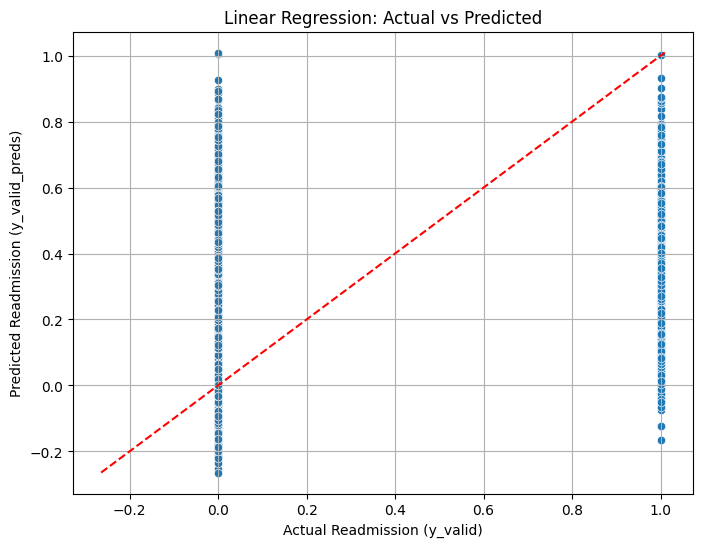

In [45]:
# Create a scatter plot of Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_valid, y=y_valid_preds)

# Add a 45-degree reference line
min_val = min(y_valid.min(), y_valid_preds.min())
max_val = max(y_valid.max(), y_valid_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel("Actual Readmission (y_valid)")
plt.ylabel("Predicted Readmission (y_valid_preds)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


### Logistic Regression

In [46]:
lr=LogisticRegression(random_state = 42, solver = 'newton-cg', max_iter = 200)
lr.fit(X_train, y_train)

y_valid_preds = lr.predict_proba(X_valid)[:,1]

print('Metrics for Validation data:')

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,y_valid_preds, 0.5)

Metrics for Validation data:
AUC:0.515
accuracy:0.705
recall:0.245
precision:0.119
specificity:0.765
prevalence:0.114
 


### KNN Model

In [47]:
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:,1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,knn_preds, 0.5)

AUC:0.546
accuracy:0.670
recall:0.343
precision:0.133
specificity:0.693
prevalence:0.114
 


### Stochastic Gradient Descent Model

In [48]:
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

print('Stochastic Gradient Descent')
print('Validation:')
sgdc_valid_auc, sgdc_valid_accuracy, sgdc_valid_recall, \
sgdc_valid_precision, sgdc_valid_specificity = print_report(y_valid, sgd_preds, 0.5)

Stochastic Gradient Descent
Validation:
AUC:0.536
accuracy:0.636
recall:0.382
precision:0.130
specificity:0.669
prevalence:0.114
 


### Decision Tree

In [49]:
dc_clf = DecisionTreeClassifier(random_state=42, max_depth = 10)
dc_clf.fit(X_train, y_train)

dc_preds_proba = dc_clf.predict_proba(X_valid)[:,1]
dc_preds = dc_clf.predict(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,dc_preds_proba, 0.5)

AUC:0.522
accuracy:0.692
recall:0.283
precision:0.125
specificity:0.743
prevalence:0.114
 


### Random Forest

In [50]:
rf_clf = RandomForestClassifier(random_state=111, max_depth = 6)

rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict(X_valid)
rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,rf_preds_proba, 0.5)

AUC:0.509
accuracy:0.650
recall:0.295
precision:0.111
specificity:0.696
prevalence:0.114
 


### Linear SVC

In [51]:
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,lsvc_preds, 0.5)

AUC:0.514
accuracy:0.878
recall:0.022
precision:0.206
specificity:0.989
prevalence:0.114
 


### Gradient Boosting Model

In [52]:
gb_clf = GradientBoostingClassifier(n_estimators = 100, criterion='friedman_mse', learning_rate = 1.0, max_depth = 3,\
                                    random_state = 111)

gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_valid)
gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,gb_preds_proba, 0.5)

AUC:0.532
accuracy:0.717
recall:0.247
precision:0.125
specificity:0.777
prevalence:0.114
 


### XGB Model

In [53]:
xgb_clf = xgb.XGBClassifier(max_depth=3, learning_rate = 1.0, use_label_encoder = False,\
                            eval_metric = 'logloss')
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict(X_valid)
xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,xgb_preds_proba, 0.5)

AUC:0.530
accuracy:0.716
recall:0.242
precision:0.123
specificity:0.778
prevalence:0.114
 


### Catboost Model

In [54]:
catb=CatBoostClassifier(iterations=200, depth=3, learning_rate=1.0, random_state = 111)
catb.fit(X_train, y_train)
catb_preds = catb.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,catb_preds, 0.5)

0:	learn: 0.6252265	total: 152ms	remaining: 30.2s
1:	learn: 0.5767867	total: 159ms	remaining: 15.8s
2:	learn: 0.5636868	total: 167ms	remaining: 10.9s
3:	learn: 0.5540146	total: 173ms	remaining: 8.46s
4:	learn: 0.5471453	total: 180ms	remaining: 7.02s
5:	learn: 0.5412621	total: 186ms	remaining: 6.02s
6:	learn: 0.5368175	total: 195ms	remaining: 5.38s
7:	learn: 0.5335210	total: 201ms	remaining: 4.81s
8:	learn: 0.5310782	total: 209ms	remaining: 4.43s
9:	learn: 0.5278982	total: 214ms	remaining: 4.06s
10:	learn: 0.5236814	total: 223ms	remaining: 3.83s
11:	learn: 0.5210734	total: 230ms	remaining: 3.6s
12:	learn: 0.5195445	total: 235ms	remaining: 3.39s
13:	learn: 0.5181888	total: 242ms	remaining: 3.21s
14:	learn: 0.5171933	total: 248ms	remaining: 3.06s
15:	learn: 0.5162488	total: 256ms	remaining: 2.94s
16:	learn: 0.5151024	total: 262ms	remaining: 2.82s
17:	learn: 0.5139175	total: 269ms	remaining: 2.72s
18:	learn: 0.5128805	total: 276ms	remaining: 2.63s
19:	learn: 0.5123011	total: 282ms	remainin

## Hyper Parameter Tuning

### Decision Tree

In [55]:
# Decision Tree - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

dc_grid = {'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'min_samples_leaf': range(1, 11, 2), ###  -->> Added a critical param
           'criterion':['gini','entropy']} # criterion for evaluating a split

dc_random = RandomizedSearchCV(estimator = dc_clf, param_distributions = dc_grid,
                               n_iter = 20,
                               cv = 10,              ### -->> chnaged cv from 2 to 5
                               scoring ='recall',   ### -->> changed fromscoring=recall_scoring,
                               verbose = 1, random_state = 111)

dc_random.fit(X_train, y_train)

dc_random.best_params_

dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, dc_hp_preds_proba)

# added later
print("Best params:", dc_random.best_params_)
print("Best CV recall:", dc_random.best_score_)
print("Validation recall:", recall_score(y_valid, dc_random.best_estimator_.predict(X_valid)))

"""
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 0.8327703475995127
Validation recall: 0.996244131455399

add all metrics from above
"""

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 5, 'criterion': 'gini'}
Best CV recall: 0.7511167836630503
Validation recall: 0.49799426934097424


"\nFitting 5 folds for each of 20 candidates, totalling 100 fits\nBest params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}\nBest CV recall: 0.8327703475995127\nValidation recall: 0.996244131455399\n\nadd all metrics from above\n"

In [56]:

recall_score(y_valid, dc_hp_preds)

0.49799426934097424

### Random Forest

In [57]:
# Random Forest - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

rf_grid = {'n_estimators':range(200,1000,200), # number of trees
           'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

rf_random = RandomizedSearchCV(estimator = rf_clf, param_distributions = rf_grid,
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

rf_random.fit(X_train, y_train)

rf_random.best_params_

rf_hp_preds = rf_random.best_estimator_.predict(X_valid)
rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, rf_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.5032339924431941

In [58]:

recall_score(y_valid, dc_hp_preds)

0.49799426934097424

### XGBoost

In [59]:
#xgboost - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

xgb_grid = params = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
        } # criterion for evaluating a split

xgb_random = GridSearchCV(estimator = xgb_clf, param_grid = xgb_grid,
                               cv = 2, scoring = recall_scoring,
                               verbose = 1)

xgb_random.fit(X_train, y_train)

xgb_random.best_params_

xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)
xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, xgb_hp_preds_proba)

Fitting 2 folds for each of 720 candidates, totalling 1440 fits


0.5370834764867698

In [60]:

recall_score(y_valid, dc_hp_preds)

0.49799426934097424

#### 4. SAVING PKL MODEL

In [ ]:
import joblib
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score, make_scorer
import numpy as np

# ---------------------------------------------------------
# TARGET: lessthan30
# ---------------------------------------------------------
target = "lessthan30"

print("\n" + "="*70)
print(f"     TUNED MODEL — {target.upper()} ")
print("="*70)

# These must already exist:
# X_train, y_train, X_valid, y_valid

prev = y_valid.mean()

# ---------------------------------------------------------
# MODEL — XGBoost Classifier
# ---------------------------------------------------------
model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=111,
    use_label_encoder=False
)

model_name = "XGBoost"

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

# ---------------------------------------------------------
# GRID SEARCH (recall optimized)
# ---------------------------------------------------------
grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=2,
    scoring=make_scorer(recall_score),
    verbose=1
)

grid.fit(X_train, y_train)

# XGBoost supports predict_proba
preds = grid.best_estimator_.predict_proba(X_valid)[:, 1]

# Your print_report returns 5 values
auc, acc, rec, prec, spec = print_report(y_valid, preds, 0.5)

print(f"\nBest Params: {grid.best_params_}")
print(f"Best CV Recall: {grid.best_score_:.4f}")
print("-"*50)
print(f"AUC:          {auc:.4f}")
print(f"Accuracy:     {acc:.4f}")
print(f"Recall:       {rec:.4f}")
print(f"Precision:    {prec:.4f}")
print(f"Specificity:  {spec:.4f}")
print(f"Prevalence:   {prev:.4f}")
print("="*70)

# ---------------------------------------------------------
# SAVE MODEL
# ---------------------------------------------------------
best_model = grid.best_estimator_
filename = f"{target}_{model_name}_smotetomek.pkl"
joblib.dump(best_model, filename)

print(f"Saved best model for {target} as '{filename}'")
print(f"Finished target: {target}")
print("="*70 + "\n")

final_models = {target: best_model}



     TUNED MODEL — LESSTHAN30 
Fitting 2 folds for each of 108 candidates, totalling 216 fits
AUC:0.536
accuracy:0.753
recall:0.192
precision:0.125
specificity:0.826
prevalence:0.114
 

Best Params: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
Best CV Recall: 0.7654
--------------------------------------------------
AUC:          0.5359
Accuracy:     0.7535
Recall:       0.1920
Precision:    0.1246
Specificity:  0.8259
Prevalence:   0.1143
Saved best model for lessthan30 as 'lessthan30_XGBoost_bestmodel.pkl'
Finished target: lessthan30

